In [1]:
import numpy as np
import matplotlib.pyplot as plt

import taichi as ti
ti.init(
    arch=ti.cpu,
    default_fp=ti.f64,
    cpu_max_num_threads=1,
    offline_cache=False,
    debug=True,
)

import jax
jax.config.update("jax_enable_x64", True)


[Taichi] version 1.7.4, llvm 15.0.4, commit b4b956fd, linux, python 3.12.13
[Taichi] Starting on arch=x64


[I 07/10/26 08:19:50.605 28963] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout


In [2]:
from tiwave.waveforms import IMRPhenomXAS
from ripplegw.waveforms.IMRPhenomXAS import gen_IMRPhenomXAS_hphctf
import bilby


In [3]:
rate = 4096
duration = 4
num = rate * duration
dt = 1/rate
df = 1/duration
fref = 20.0
fmin = 20.0
fmax = 2048.0
appro = "IMRPhenomXAS"

freqs = np.fft.rfftfreq(num, dt)
mask = (freqs >= fmin) * (freqs <= fmax)
freqs = freqs[mask]
display(freqs)

params = dict(
    mass_1=36.0,
    mass_2=29.0,
    luminosity_distance=800.0,
    reference_phase=1.2,
    chi_1=-0.4,
    chi_2=0.02,
    inclination=0.4,
    # coalescence_time=10.0,
    coalescence_time=0.0,
)
params = bilby.gw.conversion.generate_mass_parameters(params)
display(params)


array([  20.  ,   20.25,   20.5 , ..., 2047.5 , 2047.75, 2048.  ],
      shape=(8113,))

{'mass_1': 36.0,
 'mass_2': 29.0,
 'luminosity_distance': 800.0,
 'reference_phase': 1.2,
 'chi_1': -0.4,
 'chi_2': 0.02,
 'inclination': 0.4,
 'coalescence_time': 0.0,
 'chirp_mass': 28.09555579546043,
 'total_mass': 65.0,
 'symmetric_mass_ratio': np.float64(0.24710059171597634),
 'mass_ratio': 0.8055555555555556}

In [4]:
wf_tiwave = IMRPhenomXAS(
    frequencies = freqs,
    reference_frequency = fref,
)
wf_tiwave.update_waveform(params)

/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/base_waveform.py:69: UserWarning: check_parameters is disable, make sure all parameters passed in are valid.
  warnings.warn(
<unknown>:10: SyntaxWarning: invalid escape sequence '\p'


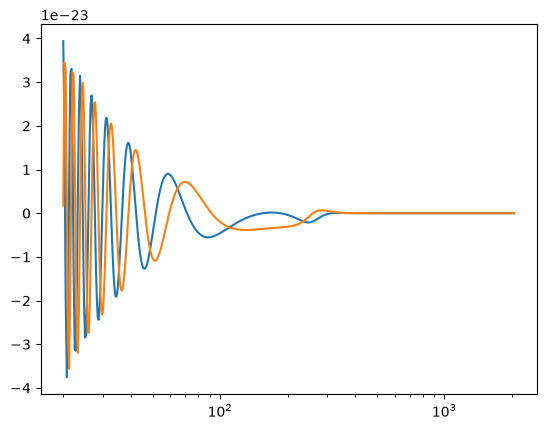

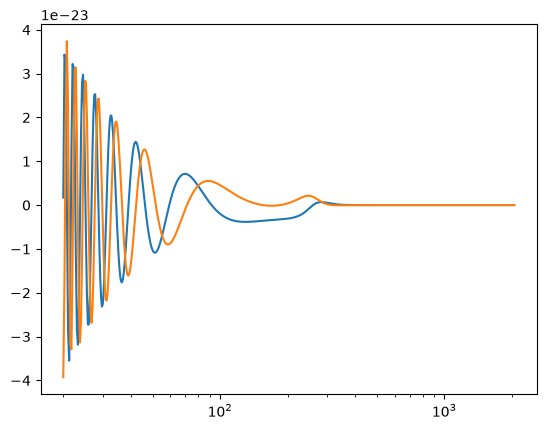

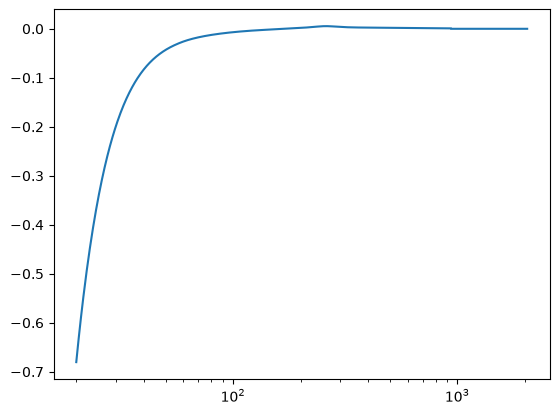

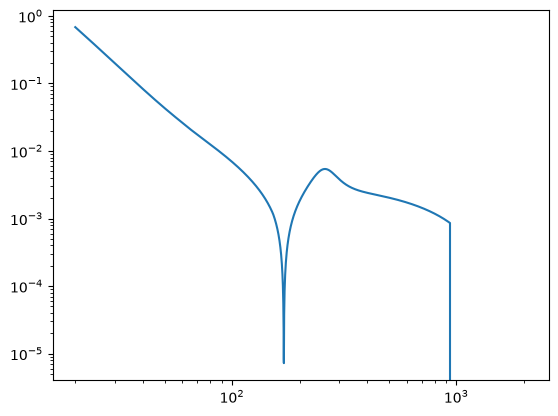

In [5]:
wf_ti = wf_tiwave.waveform_container_numpy
wf_ti['plus'] *=  np.exp(-1j * 2 * np.pi * freqs * params['coalescence_time'])
wf_ti['cross'] *= np.exp(-1j * 2 * np.pi * freqs * params['coalescence_time'])
wf_ti['tf'] += params['coalescence_time']

plt.figure()
plt.semilogx(freqs, wf_ti['plus'].real)
plt.semilogx(freqs, wf_ti['plus'].imag)

plt.figure()
plt.semilogx(freqs, wf_ti['cross'].real)
plt.semilogx(freqs, wf_ti['cross'].imag)

plt.figure()
plt.semilogx(freqs, wf_ti['tf'])

plt.figure()
plt.loglog(freqs, np.abs(wf_ti['tf']))



In [6]:
params_rp = np.array(
    [
        params['chirp_mass'],
        params['symmetric_mass_ratio'],
        params['chi_1'],
        params['chi_2'],
        params['luminosity_distance'],
        params['coalescence_time'],
        params['reference_phase'],
        params['inclination'],
    ]
    )
wf_rp = gen_IMRPhenomXAS_hphctf(freqs, params_rp, fref)

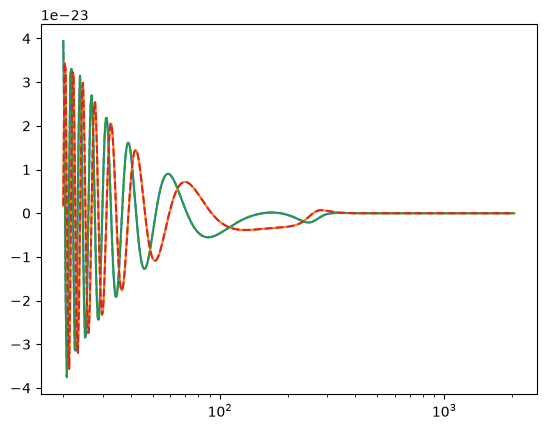

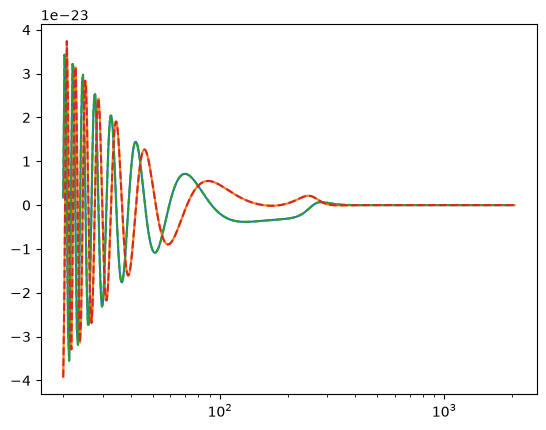

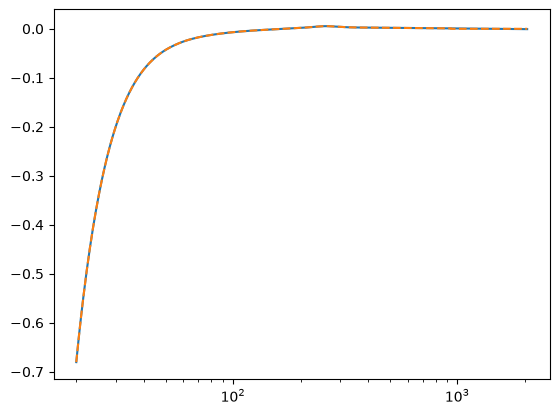

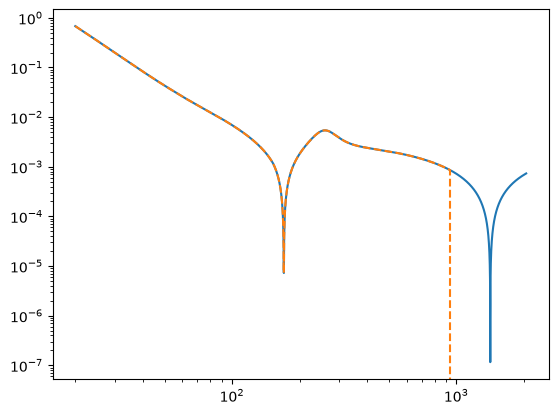

In [7]:

plt.figure()
plt.semilogx(freqs, wf_rp[0].real)
plt.semilogx(freqs, wf_rp[0].imag)
plt.semilogx(freqs, wf_ti['plus'].real, linestyle='dashed')
plt.semilogx(freqs, wf_ti['plus'].imag, linestyle='dashed')

plt.figure()
plt.semilogx(freqs, wf_rp[1].real)
plt.semilogx(freqs, wf_rp[1].imag)
plt.semilogx(freqs, wf_ti['cross'].real, linestyle='dashed')
plt.semilogx(freqs, wf_ti['cross'].imag, linestyle='dashed')

plt.figure()
plt.semilogx(freqs, wf_rp[2])
plt.semilogx(freqs, wf_ti['tf'], linestyle='dashed')

plt.figure()
plt.loglog(freqs, np.abs(wf_rp[2]))
plt.loglog(freqs, np.abs(wf_ti['tf']), linestyle='dashed')


In [8]:
np.testing.assert_allclose(wf_ti['plus'], wf_rp[0])
np.testing.assert_allclose(wf_ti['cross'], wf_rp[1])
np.testing.assert_allclose(wf_ti['tf'], wf_rp[2])

AssertionError: 
Not equal to tolerance rtol=1e-07, atol=0

Mismatched elements: 4444 / 8113 (54.8%)
First 5 mismatches are at indices:
 [3669]: 0.0 (ACTUAL), 0.0008578882229891787 (DESIRED)
 [3670]: 0.0 (ACTUAL), 0.0008573361362649647 (DESIRED)
 [3671]: 0.0 (ACTUAL), 0.0008567841808054937 (DESIRED)
 [3672]: 0.0 (ACTUAL), 0.0008562323565763936 (DESIRED)
 [3673]: 0.0 (ACTUAL), 0.0008556806635432899 (DESIRED)
Max absolute difference among violations: 0.00085789
Max relative difference among violations: 1.
 ACTUAL: array([-0.68041 , -0.655706, -0.632157, ...,  0.      ,  0.      ,
        0.      ], shape=(8113,))
 DESIRED: array([-0.68041 , -0.655706, -0.632157, ..., -0.000733, -0.000733,
       -0.000733], shape=(8113,))